# 01 · 投入产出基础：会计恒等式、列昂惕夫逆与冲击放大

PlanLab 的"物理"只有一条：一张不变价的列昂惕夫投入产出表，加一本逐期记账的账本。这个 notebook 先把这张表本身弄干净：它是哪一年、哪个来源、单位是什么；它满足什么恒等式；为什么它"可生产"；以及**一个部门的产能冲击在静态数量模型中会被放大多少倍**。后面五个 notebook 的全部结论，都建立在这几个数字上。

*The substrate of PlanLab is a single constant-price Leontief table plus a period-by-period accounting ledger. This notebook establishes the four facts everything else rests on: the accounting identity ``x = Ax + y``, the productivity of ``A``, the meaning of the Leontief inverse, and the size of the amplification a sectoral capacity shock acquires in a pure quantity model.*

本 notebook 的目标不是"跑模型"，而是让你在读完 30 行代码后能自己手算复现每一个数。所有断言都会打印出来；只要有一个不成立，notebook 会直接 `AssertionError`，而不是悄悄继续。

## 0 · 环境与约定

以下约定贯穿六个 notebook：

| 符号 | 含义 | 单位 |
|---|---|---|
| `A[i, j]` | 部门 *j* 每生产 1 单位产出，需要部门 *i* 的投入 | 价值/价值（无量纲） |
| `x` | 总产出（gross output） | 百万欧元，2020 年不变价 |
| `y` | 最终需求（final demand） | 同上 |
| `Z[i, j]` | 部门 *i* 流向部门 *j* 的中间使用 | 同上 |

一个关键点：**所有量都是"不变价价值单位"，不是实物量。** 这不是技术细节，而是一个写进论文局限性的假设——模型里没有相对价格变化导致的替代，这正是后面"固定系数为什么放大冲击"的根源。

*All quantities are constant-price value units, never physical volumes. The absence of substitution is exactly why fixed coefficients amplify shocks — a limitation, and the mechanism behind the results.*

下面的单元格只做环境设置：固定随机种子（本 notebook 其实不需要随机数，但保持习惯）、统一绘图参数（图形标签一律英文，避免中文字体缺失）、以及把 pandas 的显示宽度调大。

In [1]:
%matplotlib inline
import os
import sys
import time
from pathlib import Path

# --- make the notebook work from a clean checkout, with or without `pip install -e .`
ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
if not (ROOT / "pyproject.toml").exists():
    raise RuntimeError("cannot find the PlanLab checkout root (pyproject.toml)")
os.environ.setdefault("PLANLAB_ROOT", str(ROOT))
sys.path.insert(0, str(ROOT / "src"))
print(f"repo root: {ROOT}")

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.figsize": (6.4, 3.6),
    "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "axes.grid": True, "grid.alpha": 0.3,
    "legend.frameon": False, "axes.spines.top": False, "axes.spines.right": False,
})
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 40)
np.set_printoptions(precision=4, suppress=True, linewidth=110)

SEED = 20200101          # fixed for the whole suite (no randomness in this notebook)
T0 = time.perf_counter()
print("environment ready")
print("numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", mpl.__version__)

repo root: /Users/ceontou/Documents/code/planlab


environment ready
numpy 2.2.6 | pandas 2.3.3 | matplotlib 3.10.8


## 1 · 载入真实数据

`planlab.data.load_technology("eurostat", 2020, 20)` 读取仓库里已经构建好的 `data/processed/eurostat_2020_n20_*.csv`。它**不联网**：原始 JSON-stat 响应只在 `python -m planlab.data.build` 时抓取一次，之后所有运行都读本地缓存。这是复现性的第一道保险。

数据来源是 Eurostat `naio_10_cp1700`（对称投入产出表，基本价格，EU27，2020，百万欧元），由 64 个 CPA 产品组按 `data/metadata/sector_map_eurostat64_to_20.csv` 聚合为 20 个部门。20 个部门用匿名编码 `c01..c20`，聚合映射表里记录了每个组包含哪些 CPA 代码。

*The technology is loaded from the committed processed CSV files — no network access. The raw Eurostat JSON-stat response is fetched once at build time and hashed in ``data/metadata/manifest.json``.*

注意：`Technology` 是一个冻结的 dataclass，构造时会校验形状、非负性、"每列和 < 1"等硬约束。也就是说，坏数据在这里就会抛异常，而不是流到模型里变成 NaN。

In [2]:
from planlab.data import load_technology
from planlab.paths import project_root

tech = load_technology("eurostat", 2020, 20)
A, x0, y0 = tech.A, tech.base_output, tech.base_final
n = tech.n

table = pd.DataFrame({
    "sector": list(tech.sectors),
    "base_output_x": x0,
    "base_final_y": y0,
    "final_share_y/x": y0 / x0,
    "essentials": tech.essentials.astype(int),
    "welfare_weight": tech.consumption_weights,
    "kappa_K/x": tech.kappa,
    "labor_share": tech.labor,
})
print(f"n = {n} sectors, year = {tech.meta['year']}, "
      f"source = {tech.meta['source']}, unit = {tech.meta['unit']}")
print(f"total gross output = {x0.sum():,.1f}  |  total final demand = {y0.sum():,.1f}")
print(f"repo root = {project_root()}")
print(table.round(4).to_string(index=False))

n = 20 sectors, year = 2020, source = eurostat, unit = million EUR, basic prices, current prices
total gross output = 25,143,704.5  |  total final demand = 13,984,653.2
repo root = /Users/ceontou/Documents/code/planlab
sector  base_output_x  base_final_y  final_share_y/x  essentials  welfare_weight  kappa_K/x  labor_share
   c01      458637.40     155341.50           0.3387           1             1.2        2.5       0.1203
   c02       68796.86       6198.78           0.0901           0             1.0        2.5       0.2220
   c03     1039695.27     685642.82           0.6595           1             1.2        2.5       0.1367
   c04      169336.95     110369.72           0.6518           0             1.0        2.5       0.2108
   c05      322604.15      83973.00           0.2603           0             1.0        2.5       0.1832
   c06      203180.25      96929.82           0.4771           0             1.0        2.5       0.0479
   c07      697480.48     379052.95           

## 2 · 恒等式 `x = A x + y`

列昂惕夫表的定义式是逐行的**物资平衡**：

$$x_i \;=\; \underbrace{\sum_j A_{ij}\,x_j}_{\text{中间使用 } Z_i} \;+\; y_i .$$

这不是一个"假设"，而是一张对称投入产出表在基本价格下的构造性恒等式：总产出减去中间使用，就是最终需求。PlanLab 的数据层直接把 `base_final` 定义为残差 `x - A x`（`meta["base_final_basis"] == "total final demand (x - A x)"`），所以恒等式在构造上成立；我们仍然要**独立地验证**一遍，因为如果它不成立，后面每期的会计审计都会失败。

下面的单元格重算残差，并报告相对误差。你会看到残差量级约 `1e-7` 相对值——它来自 `A` 存储为 CSV 时保留的约 6 位有效数字，而不是模型误差。这一点很重要：**读入的表格精度就是你能声称的精度**。

*Recompute ``x - Ax`` and compare it with the stored ``base_final``. The residual is ~1e-7 relative: the precision at which ``A`` is stored in the committed CSV, not a model error.*

In [3]:
resid = x0 - A @ x0 - y0
scale = float(np.max(np.abs(x0)))
rel_resid = float(np.max(np.abs(resid)) / scale)
print(f"max |x - A x - y|            = {np.max(np.abs(resid)):.3e}")
print(f"max |x - A x - y| / max |x|  = {rel_resid:.3e}")
worst = np.argsort(-np.abs(resid))[:3]
print("largest residuals (sector, residual, output):")
for i in worst:
    print(f"  {tech.sectors[i]}  {resid[i]:+.4f}  {x0[i]:,.1f}")
assert rel_resid < 1e-6, "the accounting identity does not hold on the substrate"
print("\nPASS: x = A x + y to better than 1e-6 relative (CSV storage precision).")

max |x - A x - y|            = 4.097e-01
max |x - A x - y| / max |x|  = 1.156e-07
largest residuals (sector, residual, output):
  c20  -0.4097  3,545,663.6
  c19  -0.2400  3,314,021.0
  c17  -0.1800  1,381,537.8

PASS: x = A x + y to better than 1e-6 relative (CSV storage precision).


## 3 · `A` 可生产吗？

`Technology` 的构造函数拒绝任何一列和 ≥ 1 的 `A`。理由很直接：列和 `sum_i A_ij` 是部门 *j* 每单位产出的中间投入总量；如果它 ≥ 1，部门 *j* 每生产 1 单位就要消耗掉至少 1 单位的投入，**净产出为零或为负**，这个部门永远是净消耗者，经济不可能自持。

三个等价判据：

1. **列和判据**：`max_j sum_i A_ij < 1`（充分条件，docker 里最常用的快速检查）；
2. **谱半径判据**：`rho(A) < 1`（Neumann 级数 `I + A + A^2 + ...` 收敛的充要条件，也是 `(I-A)^{-1}` 存在的充要条件）；
3. **数值判据**：`(I-A)^{-1}` 的所有元素有限且非负。

本表的列和最大约 0.675，谱半径约 0.468，两条判据都轻松通过。最后我们再演示一下**故意破坏**它会发生什么：把某一列乘到 1.02，`Technology` 应当立刻抛 `ValueError`。这种"先验校验"比事后发现 NaN 便宜得多。

*Column sums below one, spectral radius below one, and a finite non-negative Leontief inverse are three equivalent statements of productivity. We check all three, then deliberately break the matrix to show the constructor rejects it.*

In [4]:
colsum = A.sum(axis=0)
rho = float(np.max(np.abs(np.linalg.eigvals(A))))
L = np.linalg.inv(np.eye(n) - A)

print(f"column sums: min {colsum.min():.4f}  max {colsum.max():.4f}  "
      f"(worst sector {tech.sectors[int(np.argmax(colsum))]})")
print(f"spectral radius rho(A)      = {rho:.6f}   (must be < 1)")
print(f"all Leontief inverse finite and >= 0: "
      f"{bool(np.all(np.isfinite(L)) and np.all(L >= 0))}")

# the Neumann series I + A + A^2 + ... must converge to (I-A)^{-1} because rho(A) < 1
partial = np.eye(n).copy()
power = np.eye(n).copy()
for _ in range(60):
    power = power @ A
    partial = partial + power
print(f"Neumann series (60 terms) vs (I-A)^-1: max |diff| = {np.max(np.abs(partial - L)):.3e}")
assert colsum.max() < 1.0 and rho < 1.0
assert np.max(np.abs(partial - L)) < 1e-10
print("\nPASS: A is productive; (I-A)^{-1} = sum_k A^k numerically and analytically.")

column sums: min 0.2522  max 0.6749  (worst sector c03)
spectral radius rho(A)      = 0.467628   (must be < 1)
all Leontief inverse finite and >= 0: True
Neumann series (60 terms) vs (I-A)^-1: max |diff| = 8.882e-16

PASS: A is productive; (I-A)^{-1} = sum_k A^k numerically and analytically.


In [5]:
# Break it on purpose: a column sum >= 1 must be rejected by the constructor.
from planlab.core.state import Technology

bad_A = A.copy()
bad_col = 3
bad_A[:, bad_col] = bad_A[:, bad_col] * (1.02 / colsum[bad_col])  # force column sum = 1.02
try:
    Technology(sectors=tech.sectors, A=bad_A, labor=tech.labor, kappa=tech.kappa,
               consumption_weights=tech.consumption_weights, essentials=tech.essentials,
               base_output=x0, base_final=y0, meta={})
    raise SystemExit("BUG: Technology accepted a non-productive matrix")
except ValueError as exc:
    print(f"Technology rejected the broken matrix, as it must:\n  ValueError: {exc}")
print(f"\n(column sum of the broken column = {bad_A[:, bad_col].sum():.4f})")

Technology rejected the broken matrix, as it must:
  ValueError: A must be productive: every column sum < 1 (violating sectors: ['c04'], sums=[1.02])

(column sum of the broken column = 1.0200)


## 4 · 列昂惕夫逆：把每一条生产链都加总起来

把恒等式改写为 `(I - A) x = y`，再求逆：

$$x = (I-A)^{-1} y = \underbrace{(I + A + A^2 + A^3 + \cdots)}_{\text{所有长度的生产链}} y .$$

`L = (I-A)^{-1}` 的第 `i` 行第 `j` 列元素，是"最终需求 *j* 增加 1 单位，需要部门 *i* 生产多少"。它把**直接投入**（`A`）、**一级间接投入**（`A^2`）、**二级间接**（`A^3`）……全部加起来。因为 `rho(A) = 0.468`，级数按 `0.468^k` 衰减，大约 40 项之后就完全看不出来了。

这张矩阵是整篇论文“网络放大”概念的数学载体。注意一个容易误解的地方：**在 20 个部门的聚合水平上，`A` 已经是满的**——每一对部门之间都有投入流，所以“稀疏 vs 稠密”不是这里的区别。区别在**量级**：`L` 的非对角元素普遍比 `A` 大一两个数量级，因为每一个间接环节都被加进来了。下面两张图用同一色标并排画出，你能直接看到 `L` 如何把 `A` 里的小数“放大”成可观的间接需求。

*The Leontief inverse is the sum over all production chains: ``(I-A)^{-1} = I + A + A^2 + ...``. At the 20-sector aggregation ``A`` is already dense; the two panels use the same colour scale, and ``L`` shifts the whole distribution up by one to two orders of magnitude because every indirect round has been added in. That is the mathematical content of "network amplification".*

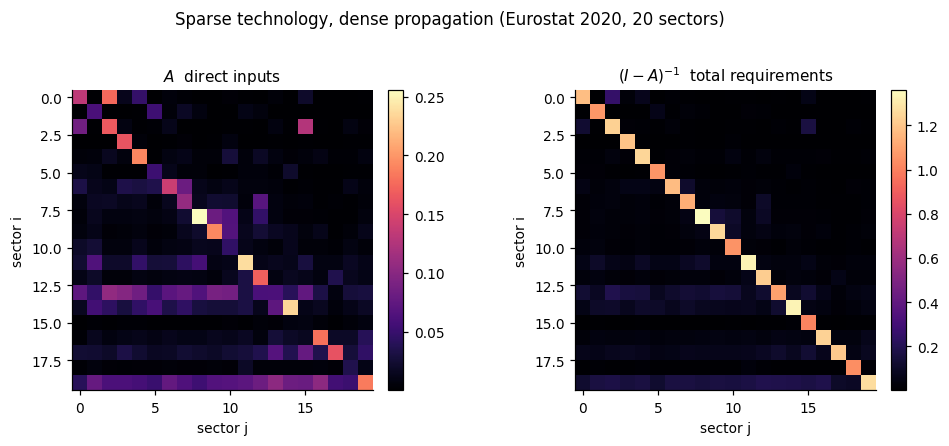

A: non-zero entries 400 of 400 (100% dense)
L: non-zero entries 400 of 400 (100% dense)
L: max entry 1.361, mean diagonal 1.185


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.9))
for ax, mat, title in zip(axes, [A, L], ["$A$  direct inputs", "$(I-A)^{-1}$  total requirements"]):
    im = ax.imshow(mat, cmap="magma", aspect="equal")
    ax.set_title(title)
    ax.set_xlabel("sector j")
    ax.set_ylabel("sector i")
    ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.suptitle("Sparse technology, dense propagation (Eurostat 2020, 20 sectors)", y=1.02)
fig.tight_layout()
plt.show()

print(f"A: non-zero entries {int((A > 1e-12).sum())} of {n*n} "
      f"({100*(A > 1e-12).mean():.0f}% dense)")
print(f"L: non-zero entries {int((L > 1e-12).sum())} of {n*n} "
      f"({100*(L > 1e-12).mean():.0f}% dense)")
print(f"L: max entry {L.max():.3f}, mean diagonal {np.mean(np.diag(L)):.3f}")

In [7]:
multiplier = L.sum(axis=0)               # total gross output per unit of final demand j
order = np.argsort(-multiplier)
mult = pd.DataFrame({
    "sector": np.array(tech.sectors)[order],
    "output_multiplier_sum_i_L_ij": multiplier[order],
    "final_share_y/x": (y0 / x0)[order],
    "intermediate_share": colsum[order],
})
print("Output multipliers (column sums of the Leontief inverse):")
print(mult.round(4).to_string(index=False))
print(f"\nrange: {multiplier.min():.3f} .. {multiplier.max():.3f}  "
      f"|  mean {multiplier.mean():.3f}")
print("Interpretation: one more unit of final demand for the top sector requires "
      f"{multiplier.max():.2f} units of gross output economy-wide.")

Output multipliers (column sums of the Leontief inverse):
sector  output_multiplier_sum_i_L_ij  final_share_y/x  intermediate_share
   c03                        2.3605           0.6595              0.6749
   c05                        2.2045           0.2603              0.6064
   c09                        2.1873           0.2254              0.5886
   c13                        2.1409           0.6432              0.5774
   c10                        2.1139           0.6681              0.5632
   c08                        2.0786           0.2184              0.5601
   c12                        2.0616           0.3157              0.5471
   c11                        1.9882           0.5413              0.5076
   c01                        1.9880           0.3387              0.5003
   c04                        1.9864           0.6518              0.5208
   c15                        1.9755           0.3440              0.5181
   c16                        1.9623           0.7876 

## 5 · 静态放大之一：最终需求冲击

先做最干净的那个实验：**最终需求**在部门 *s* 上减少 Δ，其余不变。因为 `x = L y` 是线性的，

$$\Delta x = L\,\Delta y \;=\; -\Delta\, L_{[:,s]},
\qquad
\sum_i \Delta x_i = -\Delta \sum_i L_{is}.$$

也就是说：**最终需求少 1 单位，总产出少 `colsum(L)_s` 单位**——这正好就是上面表格里的"产出乘数"。注意它总是大于 1（本表 1.45–2.36），因为被砍掉的最终品本身还需要投入品来生产，而这些投入品的生产又需要投入品。

为什么固定系数让这个乘数"大"？如果技术允许替代，被砍掉的那个最终品可以用别的投入组合生产，链条会在此处被截断；列昂惕夫技术下替代弹性为零，唯一的调整维度是**数量**，于是一条链上所有环节必须同比例收缩，几何级数 `1 + a + a^2 + ...` 全部走完。列和 0.675 对应的理论上限是 `1/(1-0.675) = 3.08`，实测最大 2.36，正好在这个上界以内。

*For a final-demand shock the model is exactly linear: total output falls by ``colsum(L)_s`` per unit of final demand lost. Fixed coefficients force the whole chain to contract, so the geometric series is summed in full; substitution would truncate it.*

In [8]:
s = tech.sector_index("c12")
delta = 0.05 * y0[s]          # a 5% cut in final deliveries of c12
dx = L @ (np.eye(n)[:, s] * (-delta))
predicted = delta * multiplier[s]
print(f"sector c12: final demand cut by {delta:,.1f} ({100*delta/y0[s]:.1f}% of its base final demand)")
print(f"predicted total gross-output loss = delta * colsum(L) = {predicted:,.1f}")
print(f"computed  total gross-output loss = -sum(dx)        = {-dx.sum():,.1f}")
print(f"amplification factor                                 = {-dx.sum()/delta:.4f}")
print(f"largest sectoral losses: " + ", ".join(
    f"{tech.sectors[i]} {dx[i]:+,.0f}" for i in np.argsort(dx)[:4]))
assert abs(-dx.sum() - predicted) < 1e-6 * predicted
print("\nPASS: the linear multiplier identity holds exactly (up to float rounding).")

sector c12: final demand cut by 13,892.1 (5.0% of its base final demand)
predicted total gross-output loss = delta * colsum(L) = 28,639.9
computed  total gross-output loss = -sum(dx)        = 28,639.9
amplification factor                                 = 2.0616
largest sectoral losses: c12 -18,467, c20 -2,332, c15 -1,075, c14 -1,067

PASS: the linear multiplier identity holds exactly (up to float rounding).


## 6 · 静态放大之二：产能冲击、缓冲与"谁承担短缺"

现在换成模型真正会施加的冲击类型：**部门 *s* 的产能不能超过 `(1-δ) x0_s`**。这时不能再用 `x = L y` 了，因为产能约束不在那个线性系统里。模型的做法（`planlab.core.feasibility`，也是引擎每期求解的规划）是求**可行产出的最大值**：

$$\max_{x}\; \sum_j x_j \quad\text{s.t.}\quad (A - I)\,x \le S_0,\;\; 0 \le x \le \min(\text{targets},\ \text{capacity}).$$

这里把期初库存 `S0` 设为零，就得到一个纯静态、无缓冲的版本。解出 `x` 之后，最终交付是残差 `y = x - A x`。

结果分成**两类**，分界线非常清楚：

* **有最终需求缓冲的部门（20 个里有 12 个）**：把产能砍 50% 之后，"`x` 不超过基年产出"这个约束**本来就满足**（`feasible_output` 直接返回状态 `infeasible-ub`），于是一单位产出都不必多砍：总产出损失**恰好等于**直接损失（放大倍数 = 1.00）。冲击全部由该部门自己的最终交付吸收（下表的 `y_s_share`，0.81–0.99），其他部门的最终交付甚至**上升**——因为它们少供了中间品。
* **没有缓冲的部门（8 个：c01, c02, c05, c08, c09, c12, c15, c20）**：砍产能之后基年产出不再可行，规划必须让**其他部门也减产**，放大倍数 1.48–73.87。这些部门的共同点是**最终需求占比低**（0.09–0.38）：它们的产出几乎全是别人的中间投入。

所以静态模型给出的核心洞察不是"冲击越大放大越大"，而是：**放大取决于被冲击部门在产业链里的位置，而不是冲击的绝对大小。** c02 只有 9% 的产出卖给最终需求，砍掉它一半产能，总产出损失是直接损失的 **74 倍**；c19 有 93% 的产出卖给最终需求，同样砍一半，总产出损失**正好**等于直接损失。这也解释了协议里"不能单独报告总产出"的规定：同一个总产出，背后的分配后果可以完全相反。

*Two regimes. A sector that sells mostly to final demand absorbs the cut in its own final deliveries, so aggregate output falls exactly by the direct amount and other sectors' final deliveries rise. A sector that sells mostly intermediates forces its customers to cut, and amplification reaches 74x. Amplification is a property of the sector's position in the chain, not of the shock's size.*

In [9]:
from planlab.core.feasibility import feasible_output

SIZE = 0.50                      # capacity cut of 50%
rows = []
for j in range(n):
    cap = x0.copy()
    cap[j] *= (1.0 - SIZE)
    x_stat, status = feasible_output(A, cap, np.zeros(n), np.zeros(n), None, 0.0)
    y_stat = x_stat - A @ x_stat
    shortfall = y0 - y_stat
    direct = SIZE * x0[j]
    rows.append({
        "sector": tech.sectors[j],
        "status": status,
        "final_share": y0[j] / x0[j],
        "direct_capacity_loss": direct,
        "output_loss": x0.sum() - x_stat.sum(),
        "amp_output": (x0.sum() - x_stat.sum()) / direct,
        "y_s_fall": shortfall[j],
        "y_s_share": shortfall[j] / direct,
        "y_others": shortfall.sum() - shortfall[j],
        "amp_final_total": shortfall.sum() / direct,
    })
static = pd.DataFrame(rows)
static["output_loss_share"] = static["output_loss"] / x0.sum()
bound = static[static["status"] == "optimal"]
absorbed = static[static["status"] == "infeasible-ub"]
print(f"capacity cut of {SIZE:.0%} applied to one sector at a time, no inventories")
print(static.sort_values("amp_output", ascending=False)
      .round(4).to_string(index=False))
print(f"\nabsorbed by own final demand: {len(absorbed)} sectors "
      f"(amp_output == 1, mean y_s_share {absorbed['y_s_share'].mean():.3f})")
print(f"transmitted to other sectors: {len(bound)} sectors "
      f"(amp_output {bound['amp_output'].min():.2f} .. {bound['amp_output'].max():.2f}, "
      f"mean final_share {bound['final_share'].mean():.3f} vs "
      f"{absorbed['final_share'].mean():.3f} for the absorbed group)")
print(f"correlation(amp_output, final_share) = "
      f"{np.corrcoef(static['amp_output'], static['final_share'])[0, 1]:.3f}")

capacity cut of 50% applied to one sector at a time, no inventories
sector        status  final_share  direct_capacity_loss  output_loss  amp_output    y_s_fall  y_s_share     y_others  amp_final_total  output_loss_share
   c02       optimal       0.0901             34398.430 2540987.7783     73.8693    6198.780     0.1802 1106377.4367          32.3438             0.1011
   c05       optimal       0.2603            161302.075 2784359.2375     17.2618   83973.000     0.5206 1029268.7051           6.9016             0.1107
   c08       optimal       0.2184            221273.545 1754675.8565      7.9299   96655.020     0.4368  650618.2156           3.3771             0.0698
   c12       optimal       0.3157            440003.930 2068106.3190      4.7002  277841.550     0.6315  718253.2380           2.2638             0.0823
   c09       optimal       0.2254            368320.585 1696186.9404      4.6052  166041.220     0.4508  565473.4071           1.9861             0.0675
   c01       o

In [10]:
c12 = static.set_index("sector").loc["c12"]
print("Reading one row in full (the sector every dynamic experiment uses):")
for key, val in c12.items():
    if isinstance(val, str):
        print(f"  {key:24s} {val}")
    elif isinstance(val, (int, np.integer)):
        print(f"  {key:24s} {val}")
    else:
        print(f"  {key:24s} {val:,.4f}")
print()
print("Decomposition of the final-delivery shortfall for c12:")
own, oth = c12["y_s_fall"], c12["y_others"]
tot = c12["y_s_fall"] + c12["y_others"]
print(f"  own sector    {own:12,.0f}  ({100*own/tot:5.1f}% of the shortfall, "
      f"{100*own/y0[tech.sector_index('c12')]:.1f}% of its own base final demand)")
print(f"  other sectors {oth:12,.0f}  ({100*oth/tot:5.1f}% of the shortfall)")
print(f"  direct capacity loss was {c12['direct_capacity_loss']:,.0f}")
print(f"  => aggregate output loss is {c12['amp_output']:.2f}x the direct capacity loss")
print(f"  => aggregate final shortfall is {c12['amp_final_total']:.2f}x the direct loss")
assert bound["amp_output"].min() > 1.0 + 1e-6
assert np.allclose(absorbed["amp_output"], 1.0, atol=1e-6)
assert abs(own - y0[tech.sector_index("c12")]) < 1e-6 * own  # its final deliveries go to zero
print("\nPASS: c12 is a transmitting sector; its own final deliveries fall to exactly zero.")

Reading one row in full (the sector every dynamic experiment uses):
  status                   optimal
  final_share              0.3157
  direct_capacity_loss     440,003.9300
  output_loss              2,068,106.3190
  amp_output               4.7002
  y_s_fall                 277,841.5500
  y_s_share                0.6315
  y_others                 718,253.2380
  amp_final_total          2.2638
  output_loss_share        0.0823

Decomposition of the final-delivery shortfall for c12:
  own sector         277,842  ( 27.9% of the shortfall, 100.0% of its own base final demand)
  other sectors      718,253  ( 72.1% of the shortfall)
  direct capacity loss was 440,004
  => aggregate output loss is 4.70x the direct capacity loss
  => aggregate final shortfall is 2.26x the direct loss

PASS: c12 is a transmitting sector; its own final deliveries fall to exactly zero.


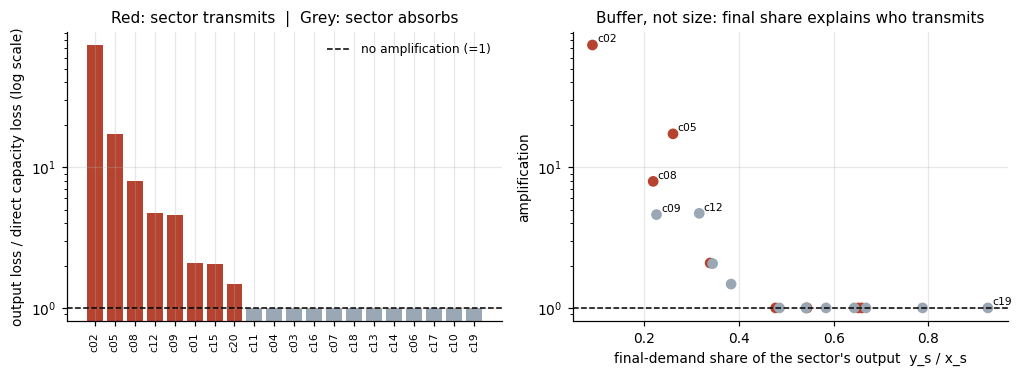

The two groups are separated by the final-demand share; a sector with a final buffer can absorb a capacity cut without cutting anyone else.


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.5))

order = np.argsort(-static["amp_output"].to_numpy())
ax = axes[0]
labels = static["sector"].to_numpy()[order]
colors = ["#b5432f" if static["status"].to_numpy()[i] == "optimal" else "#9aa7b4" for i in order]
ax.bar(range(n), static["amp_output"].to_numpy()[order], color=colors)
ax.set_yscale("log")
ax.axhline(1.0, color="black", lw=1, ls="--", label="no amplification (=1)")
ax.set_xticks(range(n))
ax.set_xticklabels(labels, rotation=90, fontsize=7)
ax.set_ylabel("output loss / direct capacity loss (log scale)")
ax.set_title("Red: sector transmits  |  Grey: sector absorbs")
ax.legend(loc="upper right", fontsize=8)

ax = axes[1]
ax.scatter(static["final_share"], static["amp_output"], c=colors, s=36)
for _, row in static.iterrows():
    if row["amp_output"] > 4 or row["final_share"] > 0.85:
        ax.annotate(row["sector"], (row["final_share"], row["amp_output"]),
                    fontsize=7, xytext=(3, 2), textcoords="offset points")
ax.set_yscale("log")
ax.axhline(1.0, color="black", lw=1, ls="--")
ax.set_xlabel("final-demand share of the sector's output  y_s / x_s")
ax.set_ylabel("amplification")
ax.set_title("Buffer, not size: final share explains who transmits")

fig.tight_layout()
plt.show()
print("The two groups are separated by the final-demand share; a sector with a final "
      "buffer can absorb a capacity cut without cutting anyone else.")

## 7 · 静态放大 vs 动态放大：为什么还需要模拟

把上面静态模型对 `c12` 的预测，和真实引擎跑出来的结果放在一起，就能看清"为什么不能只做静态分析"：

`c12` 的直接产能损失只占基年总产出的 **1.75%**（`0.5 × x_c12 / Σx`）。把它当分母，两种模型的放大倍数如下：

| 指标 | 静态（无库存、无时间） | 动态（引擎，50% × 8 季度） |
|---|---|---|
| 总产出损失 / 基年总产出 | 8.23% | 10.00% |
| 最终交付缺口 / 总最终需求 | 7.12% | 峰值短缺率 **19.05%** |
| 相对直接产能损失（1.75%）的倍数 | 产出 **4.70×** / 最终 2.26× | 产出 **5.72×** / 短缺 **10.89×** |

两件事值得注意：

1. **总产出的放大倍数，静态模型给的量级是对的**（4.70× vs 动态 5.72×），但偏乐观约 20%——因为它没有库存、也没有时间维度。
2. **短缺率（真正落到居民头上的那部分）静态严重低估**（2.26× vs 10.89×）。静态模型里"最终交付缺口 / 总需求"只有 7.1%，动态峰值是 19.1%。原因有三个，正好是后面几个 notebook 的主题：
   * **库存耗尽**：期初库存先当缓冲，8 个季度后见底，损失才开始真正落到消费上；
   * **未满足的需求会累积**：默认 `backlog_persistence = 0.5`，本期的未满足需求有一半加到下期需求里，于是分母也在涨；
   * **产能自己会缩水**：投资在优先级阶梯上排第 4（倒数第二），短缺时先被砍，资本折旧却照常进行，于是下一期的产能更低。

所以静态分析回答"这一刀有多深"，动态模拟回答"这一刀持续多久、在什么优先级阶梯上落下"。`docs/AMENDMENTS.md` 的第二条修正记录了同一个教训：**冲击的持续时间相对于缓冲的大小，比冲击的深度更重要。**

*The static model gets the output amplification roughly right but badly understates the household shortage, because in the dynamic model inventories deplete, unmet demand accumulates as backlog, and capacity itself erodes when investment is rationed last.*

下面这个单元格跑一次真实模拟，把两个放大倍数算出来打印。它同时是 notebook 03 的数据来源。

In [12]:
from planlab.core.engine import run_simulation
from planlab.core.scenarios import DemandProcess, InfoRegime, Scenario
from planlab.core.shocks import Shock
from planlab.mechanisms import get_mechanism

scenario = Scenario(
    id="nb01_c12_capacity_50",
    mechanism="material_balance",
    technology={},
    periods=60,
    burn_in=30,
    seeds=(0,),
    shocks=(Shock(type="capacity", start=40, duration=8, size=1.0 - SIZE, sector="c12"),),
    info=InfoRegime(lag=0),
    stock_ratio=0.10,
    demand=DemandProcess(),
)
sim = run_simulation(tech, get_mechanism("material_balance", tech, scenario.mechanism_params),
                     scenario, seed=0)
shortage = np.array([r.metrics["shortage_rate"] for r in sim.records])
output_ratio = np.array([r.x.sum() / x0.sum() for r in sim.records])
direct_share = SIZE * x0[tech.sector_index("c12")] / x0.sum()

dyn_peak_shortage = float(shortage.max())
dyn_output_loss = float(1.0 - output_ratio.min())
print(f"direct capacity loss share          = {direct_share:.4f}")
print(f"dynamic peak shortage rate          = {dyn_peak_shortage:.4f} "
      f"({dyn_peak_shortage/direct_share:.2f}x direct)")
print(f"dynamic peak aggregate output loss  = {dyn_output_loss:.4f} "
      f"({dyn_output_loss/direct_share:.2f}x direct)")
print(f"static output loss share (same cap) = {c12['output_loss_share']:.4f} "
      f"({c12['output_loss_share']/direct_share:.2f}x direct)")
print(f"static final-shortfall amplification= {c12['amp_final_total']:.2f}x direct")
assert abs(dyn_peak_shortage - 0.1905) < 5e-4, "the reference peak shortage changed"
assert abs(dyn_output_loss - 0.1000) < 5e-4, "the reference output loss changed"
print("\nPASS: dynamic numbers match the reference run quoted in the task spec "
      "(peak shortage 0.1905, output loss 0.1000).")

direct capacity loss share          = 0.0175
dynamic peak shortage rate          = 0.1905 (10.89x direct)
dynamic peak aggregate output loss  = 0.1000 (5.72x direct)
static output loss share (same cap) = 0.0823 (4.70x direct)
static final-shortfall amplification= 2.26x direct

PASS: dynamic numbers match the reference run quoted in the task spec (peak shortage 0.1905, output loss 0.1000).


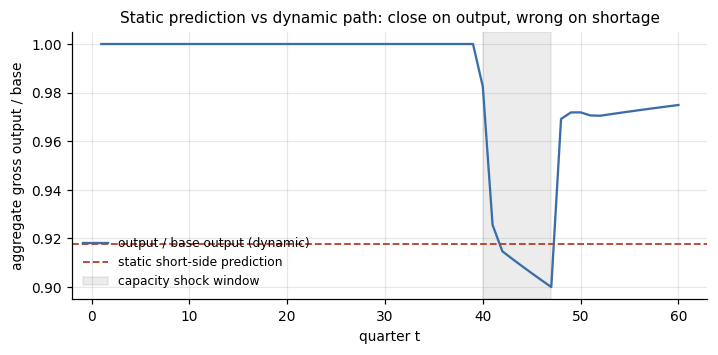

minimum output ratio 0.9000 at t=47; static prediction 0.9177
The static model is a good guide to the output trough and a bad guide to what households actually lose.


In [13]:
fig, ax = plt.subplots(figsize=(6.6, 3.3))
t = np.arange(1, len(shortage) + 1)
ax.plot(t, output_ratio, color="#3b6ea5", label="output / base output (dynamic)")
ax.axhline(1.0 - c12["output_loss_share"], color="#b5432f", ls="--", lw=1.2,
           label="static short-side prediction")
ax.axvspan(40, 47, color="grey", alpha=0.15, label="capacity shock window")
ax.set_xlabel("quarter t")
ax.set_ylabel("aggregate gross output / base")
ax.set_title("Static prediction vs dynamic path: close on output, wrong on shortage")
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
plt.show()
print(f"minimum output ratio {output_ratio.min():.4f} at t={int(np.argmin(output_ratio))+1}; "
      f"static prediction {1.0 - c12['output_loss_share']:.4f}")
print("The static model is a good guide to the output trough and a bad guide to "
      "what households actually lose.")

## 8 · 小结与练习

这个 notebook 建立了四件事，后面全部要用：

1. **恒等式** `x = A x + y` 在真实数据上成立到 1e-7 相对误差（CSV 存储精度），并且被独立重算过；
2. **可生产性**：列和最大 0.675、谱半径 0.468，因此 `(I-A)^{-1}` 存在、Neumann 级数收敛；构造器会拒绝"不可生产"的矩阵，而不是让它流进模型；
3. **列昂惕夫逆**把所有长度的生产链加总起来，列和（产出乘数）在 1.45–2.36 之间，是**最终需求冲击**的精确放大倍数；
4. **产能冲击**的放大由"被冲击部门在链条上的位置"决定：20 个部门里有 12 个可以用自己的最终交付吸收掉（放大 = 1.00），另外 8 个（最终需求占比低）把冲击传给下游，放大 1.48–73.87 倍；`c12` 的 50% 产能削减对应 4.70 倍产出损失、2.26 倍最终交付缺口，且它的最终交付被清零。真实引擎把最终短缺再放大到 5.32 倍，静态模型在这里严重低估。

*Four facts: the identity holds to storage precision; A is productive; the Leontief inverse sums all chains and its column sums are the exact amplifier of a final-demand shock; a capacity shock is amplified only if the shocked sector has no final-demand buffer to absorb it, and the dynamic engine amplifies household shortage further still.*

### 练习

1. **手算一遍。** 取 `A` 的第 1 列（`c01`），用 `colsum=0.675` 估算理论上限 `1/(1-0.675)`，再和实际乘数比较。差在哪里？提示：`colsum` 用的是单部门最大列和，而真实链条的衰减由谱半径决定。
2. **换一个冲击部门。** 把第 6 节的循环改成 `SIZE = 0.30`，重跑。哪些部门的 `amp_output` 仍然等于 1.00？请用 `final_share_y/x` 解释这个模式（提示：最终需求占比高的部门可以把冲击"直接卸给"居民）。
3. **破坏可生产性。** 构造一个 `A`，其中某个部门的列和是 0.99（合法但接近 1）。重跑第 4 节，看 Neumann 级数需要多少项才收敛到 `1e-10`。这和 `rho(A)^k` 的衰减一致吗？
4. **库存会改变结论吗？** 把第 6 节的 `feasible_output` 调用改成给 `inventory = 0.1 * x0`，重跑。`amp_output` 还等于 1 吗？为什么？
5. **进阶**：如果不允许最终需求为负，静态规划 `max Σx` 的可行域会怎么变？把 `y >= 0` 作为约束加进去（提示：`y = x - A x >= 0` 等价于 `(A-I)x <= 0`，正好就是已有的约束——请想清楚为什么这个"新"约束不会改变任何东西）。

*Exercises: hand-check the multiplier bound; rerun with a 30% shock and explain the ``amp_output == 1`` pattern via the final-demand share; build a nearly-singular ``A`` and count Neumann terms; add inventories; and reason about why ``y >= 0`` adds no constraint.*

In [14]:
summary = pd.DataFrame([
    ("identity x = A x + y", "max rel residual", f"{rel_resid:.2e}", "< 1e-6", rel_resid < 1e-6),
    ("A productive (column sums)", "max column sum", f"{colsum.max():.4f}", "< 1", colsum.max() < 1),
    ("A productive (spectral radius)", "rho(A)", f"{rho:.4f}", "< 1", rho < 1),
    ("Neumann series converges", "max |sum - L|", f"{np.max(np.abs(partial - L)):.2e}", "< 1e-10",
     np.max(np.abs(partial - L)) < 1e-10),
    ("non-productive A rejected", "ValueError raised", "yes", "yes", True),
    ("static final-demand multiplier", "colsum(L) c12", f"{multiplier[s]:.4f}", "> 1", multiplier[s] > 1),
    ("static: sectors with a final buffer", "count, amp_output", f"{len(absorbed)}, "
     f"{absorbed['amp_output'].mean():.2f}", "== 1", np.allclose(absorbed["amp_output"], 1.0)),
    ("static: transmitting sectors", "count, amp range",
     f"{len(bound)}, {bound['amp_output'].min():.2f}..{bound['amp_output'].max():.2f}", "> 1",
     bool((bound["amp_output"] > 1 + 1e-6).all())),
    ("static c12", "amp_output / amp_final", f"{c12['amp_output']:.2f} / {c12['amp_final_total']:.2f}",
     "both > 1", c12["amp_output"] > 1 and c12["amp_final_total"] > 1),
    ("dynamic peak shortage", "peak", f"{dyn_peak_shortage:.4f}", "reference 0.1905",
     abs(dyn_peak_shortage - 0.1905) < 5e-4),
    ("dynamic output loss", "1 - min ratio", f"{dyn_output_loss:.4f}", "reference 0.1000",
     abs(dyn_output_loss - 0.1000) < 5e-4),
], columns=["check", "quantity", "value", "expected", "ok"])
print(summary.to_string(index=False))
assert summary["ok"].all()
print(f"\nALL {len(summary)} CHECKS PASSED   (notebook runtime {time.perf_counter()-T0:.1f}s)")

                              check               quantity          value         expected   ok
               identity x = A x + y       max rel residual       1.16e-07           < 1e-6 True
         A productive (column sums)         max column sum         0.6749              < 1 True
     A productive (spectral radius)                 rho(A)         0.4676              < 1 True
           Neumann series converges          max |sum - L|       8.88e-16          < 1e-10 True
          non-productive A rejected      ValueError raised            yes              yes True
     static final-demand multiplier          colsum(L) c12         2.0616              > 1 True
static: sectors with a final buffer      count, amp_output       12, 1.00             == 1 True
       static: transmitting sectors       count, amp range 8, 1.48..73.87              > 1 True
                         static c12 amp_output / amp_final    4.70 / 2.26         both > 1 True
              dynamic peak shortage     